# Kolmogorov-Arnold additive models from scratch: B-spline edge functions in PyTorch (the KANVAS model)

A Kolmogorov-Arnold additive model (KAAM) gives every input feature its own learnable curve and adds the curves up:

    risk = sigmoid( phi_1(x_1) + phi_2(x_2) + ... + phi_10(x_10) + bias ),   phi_i(x) = w_i SiLU(x) + sum_j c_ij B_j(x)

Each curve is a cubic B-spline plus a small SiLU term, as in the edge functions of Kolmogorov-Arnold networks (Liu
et al., 2024), but with no hidden layer, so features never interact and every prediction splits exactly into one
contribution per feature. This notebook builds the model from the Cox-de Boor recursion up, checks it on synthetic
data, trains it on 539,816 GPU tasks to predict failure, and reads the learned curves.

- Data: `kanvas_tasks_1h.parquet` from the dataset [alibaba-gpu-trace-2020](https://www.kaggle.com/datasets/swapnilshukla007/alibaba-gpu-trace-2020), derived from [cluster-trace-gpu-v2020](https://github.com/alibaba/clusterdata/tree/master/cluster-trace-gpu-v2020) (CC BY 4.0, Weng et al., NSDI 2022)
- Run time: about 5 minutes on a Kaggle CPU notebook; the model has 151 parameters, so no GPU is needed
- Part 4 of a five-part series from the KANVAS project. Live app: [kanvas.streamlit.app](https://kanvas.streamlit.app) | Code: [github.com/Swapnil007-Curious/KANVAS](https://github.com/Swapnil007-Curious/KANVAS) | Paper: link to be added

## Contents

1. Setup
2. B-splines from scratch: knots and the Cox-de Boor recursion
3. One edge function, then the additive model
4. Sanity check: recovering known curves from synthetic data
5. Training on the GPU trace: fast fitting with a precomputed design
6. Reading the ten learned curves
7. What the smoothness penalty does
8. Users the model has never seen
9. What we found, limitations and next steps

## 1. Setup

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths. On Kaggle the defaults apply; the two environment variables let the same notebook run elsewhere.
INPUT_ROOT = Path(os.environ.get("KAGGLE_INPUT_ROOT", "/kaggle/input"))
WORKING = Path(os.environ.get("KAGGLE_WORKING", "/kaggle/working"))
WORKING.mkdir(parents=True, exist_ok=True)

# FAST = True runs a smaller version for a quick check on a small machine. Kaggle runs use the full data.
FAST = os.environ.get("KANVAS_FAST", "0") == "1"
SEED = 42  # one seed for every random choice in the notebook

# Okabe-Ito colours, chosen so the series stay distinct for the common forms of colour blindness.
BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, YELLOW, BLACK = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000")
PALETTE = [BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, BLACK]
SEQUENTIAL_CMAP = "cividis"  # one perceptually uniform ramp for heatmaps

mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
    "axes.prop_cycle": mpl.cycler(color=PALETTE), "legend.frameon": False,
})
np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)


def find_data_dir(required, root=INPUT_ROOT, max_depth=4):
    """Return the first folder under ``root`` that contains every file in ``required``.

    Kaggle mounts attached datasets under /kaggle/input, and the exact sub-path has changed over the
    years, so the notebook searches for the files instead of hard-coding one layout.
    """
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        if all(name in filenames for name in required):
            return Path(dirpath)
        if depth >= max_depth:
            dirnames[:] = []
    raise FileNotFoundError(
        f"Could not find {list(required)} under {root}. Attach the dataset 'alibaba-gpu-trace-2020' "
        "(Add Input > Datasets) and run again.")


def save_cover(draw, path=None):
    """Draw a 1280x720 cover image with ``draw(ax)`` and save it as cover.png in the working folder."""
    path = WORKING / "cover.png" if path is None else path
    fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
    draw(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=100)
    plt.close(fig)
    return path


print(f"pandas {pd.__version__}, numpy {np.__version__}, matplotlib {mpl.__version__}; FAST = {FAST}")

pandas 3.0.6, numpy 2.4.6, matplotlib 3.11.2; FAST = False


In [2]:
import importlib
import subprocess
import sys


def ensure(package, pip_spec):
    """Import ``package``; if it is missing, install the pinned ``pip_spec`` (needs internet) and import it."""
    try:
        return importlib.import_module(package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_spec], check=True)
        return importlib.import_module(package)


lgb = ensure("lightgbm", "lightgbm==4.7.0")  # preinstalled on Kaggle; the pin is only a fallback
import sklearn
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

N_THREADS = 4  # Kaggle CPU notebooks have 4 cores; a fixed count keeps LightGBM results reproducible
FEATURES = ["plan_cpu", "plan_mem", "plan_gpu", "inst_num", "avg_cpu_usr", "avg_gpu_util", "avg_cpu_kernel",
            "avg_load_1", "cap_gpu", "avg_net_receive"]
FEATURE_NOTES = {  # where each feature comes from, for labels and tables
    "plan_cpu": "requested CPU (100 = 1 core)", "plan_mem": "requested memory (GB)",
    "plan_gpu": "requested GPU per instance (100 = 1 GPU)", "inst_num": "instances requested",
    "avg_cpu_usr": "machine CPU user time, previous hour", "avg_gpu_util": "machine GPU utilisation, previous hour",
    "avg_cpu_kernel": "machine CPU kernel time, previous hour", "avg_load_1": "machine load, previous hour",
    "cap_gpu": "GPUs on the machine", "avg_net_receive": "machine network bytes received, previous hour",
}
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)  # train, validation, test
CLIP_QUANTILES = (0.01, 0.99)         # per-feature clipping, fitted on the training split only
LR_C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]  # inverse regularisation strengths for logistic regression


def say(text):
    """Render a line of markdown in the output (used for takeaways that quote numbers computed above)."""
    display(Markdown(text))


def load_tasks():
    """Load the KANVAS task table: ten features, the failure label, start time and an integer user id."""
    path = find_data_dir(["kanvas_tasks_1h.parquet"]) / "kanvas_tasks_1h.parquet"
    df = pd.read_parquet(path)
    if FAST:
        df = df.sample(n=100_000, random_state=SEED).sort_index()
    return df.reset_index(drop=True)


def random_split(y, seed=SEED):
    """Stratified 70/15/15 split: the test part is drawn first, then validation from the rest."""
    idx = np.arange(len(y))
    n_test = int(np.ceil(SPLIT_FRACTIONS[2] * len(y)))
    n_val = int(np.ceil(SPLIT_FRACTIONS[1] * len(y)))
    rest, test = train_test_split(idx, test_size=n_test, random_state=seed, stratify=y)
    train, val = train_test_split(rest, test_size=n_val, random_state=seed, stratify=y[rest])
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


def user_grouped_folds(y, users, n_folds=5, seed=0):
    """Folds where every user's tasks sit in exactly one of train, validation or test."""
    outer = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    folds = []
    for k, (rest, test) in enumerate(outer.split(np.zeros(len(y)), y, users)):
        inner = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=k)
        tr, va = next(inner.split(np.zeros(len(rest)), y[rest], users[rest]))
        folds.append({"train": np.sort(rest[tr]), "val": np.sort(rest[va]), "test": np.sort(test)})
    return folds


class Scaler:
    """Clip each feature to training quantiles, then min-max scale with the training range."""

    def fit(self, X):
        lo, hi = X.quantile(CLIP_QUANTILES[0]), X.quantile(CLIP_QUANTILES[1])
        clipped = X.clip(lo, hi, axis=1)
        self.lo, self.hi = lo, hi
        self.min, self.max = clipped.min(), clipped.max()
        self.max = self.max.where(self.max > self.min, self.min + 1.0)
        return self

    def transform(self, X):
        return ((X.clip(self.lo, self.hi, axis=1) - self.min) / (self.max - self.min)).astype("float32")

    def to_raw(self, feature, scaled):
        return self.min[feature] + np.asarray(scaled) * (self.max[feature] - self.min[feature])

    def to_scaled(self, feature, raw):
        return (np.asarray(raw, dtype=float) - self.min[feature]) / (self.max[feature] - self.min[feature])


def fit_lr(Xtr, ytr, Xva, yva):
    """Logistic regression with C chosen on validation AUC; return (model, chosen C)."""
    best = None
    for c in LR_C_GRID:
        m = LogisticRegression(C=c, max_iter=5_000).fit(Xtr, ytr)
        auc = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
        if best is None or auc > best[0]:
            best = (auc, c, m)
    return best[2], best[1]


def bootstrap_auc(y, p, n_boot=1000, seed=SEED):
    """Test ROC-AUC with a 95% percentile bootstrap interval over test tasks."""
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            stats.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(stats, 2.5), np.percentile(stats, 97.5)


print(f"lightgbm {lgb.__version__}, scikit-learn {sklearn.__version__}")

lightgbm 4.7.0, scikit-learn 1.9.1


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(N_THREADS)
NUM_KNOTS = 10      # interior knots per feature
SPLINE_ORDER = 3    # cubic B-splines
GRID_EXTEND = 0.1   # margin beyond [0, 1] so slightly out-of-range inputs stay on the grid
BATCH_SIZE = 2048
LEARNING_RATE = 0.01
MAX_EPOCHS = 30 if FAST else 500
PATIENCE = 10       # epochs without a validation AUC gain before stopping
MIN_DELTA = 1e-4    # smallest validation AUC gain that counts as progress


def set_seed(seed):
    """Seed numpy and torch."""
    np.random.seed(seed)
    torch.manual_seed(seed)


def clamped_knots(x_min=0.0, x_max=1.0, num_knots=NUM_KNOTS, order=SPLINE_ORDER, extend=GRID_EXTEND):
    """Uniform clamped knot vector: the two end knots repeated order + 1 times, num_knots evenly spaced inside."""
    low, high = x_min - extend, x_max + extend
    interior = torch.linspace(low, high, num_knots + 2)[1:-1]
    return torch.cat([torch.full((order + 1,), low), interior, torch.full((order + 1,), high)])


def bspline_basis(x, knots, order=SPLINE_ORDER):
    """All B-spline basis functions at x via the Cox-de Boor recursion; returns (len(x), n_basis).

    Degree 0: N_i0(x) = 1 on [t_i, t_i+1), else 0. Degree p: a weighted blend of two degree p-1 neighbours,
    N_ip = (x - t_i)/(t_i+p - t_i) N_i,p-1 + (t_i+p+1 - x)/(t_i+p+1 - t_i+1) N_i+1,p-1, with 0/0 taken as 0.
    """
    t = knots
    xu = x.unsqueeze(-1)
    bases = ((xu >= t[:-1]) & (xu < t[1:])).to(x.dtype)
    at_top = x == t[-1]  # the right end belongs to the last non-empty span
    if at_top.any():
        bases = bases.clone()
        last = int(torch.nonzero(t[1:] > t[:-1])[-1])
        bases[at_top, last] = 1.0
    for p in range(1, order + 1):
        left_den = t[p:-1] - t[:-(p + 1)]
        right_den = t[p + 1:] - t[1:-p]
        left = torch.where(left_den == 0, torch.zeros_like(left_den), 1.0 / left_den)
        right = torch.where(right_den == 0, torch.zeros_like(right_den), 1.0 / right_den)
        bases = (xu - t[:-(p + 1)]) * left * bases[:, :-1] + (t[p + 1:] - xu) * right * bases[:, 1:]
    return bases


class BSplineEdge(nn.Module):
    """One learnable function of one feature: phi(x) = w * SiLU(x) + sum_j c_j B_j(x)."""

    def __init__(self, x_min=0.0, x_max=1.0):
        super().__init__()
        self.register_buffer("knots", clamped_knots(x_min, x_max))
        self.n_basis = len(self.knots) - SPLINE_ORDER - 1
        self.spline_weight = nn.Parameter(torch.randn(self.n_basis) * 0.1)  # small start: nearly flat curves
        self.base_weight = nn.Parameter(torch.randn(()) * 0.1)

    def forward(self, x):
        x = torch.clamp(x, float(self.knots[0]), float(self.knots[-1]))
        return bspline_basis(x, self.knots) @ self.spline_weight + self.base_weight * F.silu(x)


class KAAM(nn.Module):
    """Kolmogorov-Arnold additive model: risk = sigmoid(sum_i phi_i(x_i) + bias)."""

    def __init__(self, feature_names):
        super().__init__()
        self.feature_names = list(feature_names)
        # one edge per feature, each fed exactly one input column, so features can never interact
        self.edges = nn.ModuleDict({name: BSplineEdge() for name in self.feature_names})
        self.bias = nn.Parameter(torch.zeros(()))

    def contributions(self, x):
        """Per-feature contributions phi_i(x_i), shape (batch, n_features), in log-odds."""
        return torch.stack([self.edges[n](x[:, i]) for i, n in enumerate(self.feature_names)], dim=1)

    def forward(self, x):
        return torch.sigmoid(self.contributions(x).sum(dim=1) + self.bias)


def design(x, knots):
    """Precomputed inputs for fast training: basis values (n, f, n_basis) and SiLU values (n, f)."""
    x = torch.from_numpy(np.array(x, dtype=np.float32))  # a writable copy (pandas may hand out read-only arrays)
    xc = torch.clamp(x, float(knots[0]), float(knots[-1]))
    basis = torch.stack([bspline_basis(xc[:, i], knots) for i in range(x.shape[1])], dim=1)
    return basis, F.silu(xc)


def roughness(coef):
    """Sum of squared second differences of the spline coefficients (0 for straight lines)."""
    return ((coef[:, 2:] - 2 * coef[:, 1:-1] + coef[:, :-2]) ** 2).sum()


def fit_kaam(d_train, y_train, d_val, y_val, lam, seed=0):
    """Fit KAAM on precomputed designs with Adam, early stopping on validation AUC; return (model, history)."""
    set_seed(seed)
    model = KAAM(FEATURES)
    coef = nn.Parameter(torch.stack([model.edges[n].spline_weight.detach() for n in FEATURES]).clone())
    base = nn.Parameter(torch.stack([model.edges[n].base_weight.detach() for n in FEATURES]).clone())
    bias = nn.Parameter(torch.zeros(()))
    params = [coef, base, bias]

    def logit(d, idx=None):
        b, s = d if idx is None else (d[0][idx], d[1][idx])
        return torch.einsum("nfk,fk->n", b, coef) + (s * base).sum(1) + bias

    opt = torch.optim.Adam(params, lr=LEARNING_RATE)
    gen = torch.Generator().manual_seed(seed)
    yt = torch.as_tensor(np.asarray(y_train, dtype=np.float32))
    n = len(yt)
    best, best_state, since, history = -np.inf, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        perm = torch.randperm(n, generator=gen)
        for start in range(0, n, BATCH_SIZE):
            idx = perm[start:start + BATCH_SIZE]
            loss = F.binary_cross_entropy_with_logits(logit(d_train, idx), yt[idx])
            if lam > 0:
                loss = loss + lam * roughness(coef)
            opt.zero_grad()
            loss.backward()
            opt.step()
        with torch.no_grad():
            auc = roc_auc_score(y_val, logit(d_val).numpy())
        history.append(auc)
        if auc > best + MIN_DELTA:
            best, since, best_state = auc, 0, [p.detach().clone() for p in params]
        else:
            since += 1
            if since >= PATIENCE:
                break
    with torch.no_grad():  # restore the best epoch and copy it into a standard KAAM module
        for i, name in enumerate(FEATURES):
            model.edges[name].spline_weight.copy_(best_state[0][i])
            model.edges[name].base_weight.copy_(best_state[1][i])
        model.bias.copy_(best_state[2])
    return model, history


def kaam_logit(model, d):
    """Logits from a fitted KAAM on a precomputed design."""
    coef = torch.stack([model.edges[n].spline_weight for n in FEATURES])
    base = torch.stack([model.edges[n].base_weight for n in FEATURES])
    with torch.no_grad():
        return (torch.einsum("nfk,fk->n", d[0], coef) + (d[1] * base).sum(1) + model.bias).numpy()


def kaam_contributions(model, d):
    """Per-feature contributions (n, n_features) from a precomputed design."""
    coef = torch.stack([model.edges[n].spline_weight for n in FEATURES])
    base = torch.stack([model.edges[n].base_weight for n in FEATURES])
    with torch.no_grad():
        return (torch.einsum("nfk,fk->nf", d[0], coef) + d[1] * base).numpy()


def shape_curve(model, feature, grid):
    """phi(feature) on a grid of scaled values."""
    with torch.no_grad():
        return model.edges[feature](torch.as_tensor(np.asarray(grid, dtype=np.float32))).numpy()

In [4]:
LAMBDAS = [0.0, 1e-4, 1e-3, 1e-2]  # smoothness penalty strengths tried on validation AUC
NET_UNIT = 1e9                     # avg_net_receive is plotted in GB instead of bytes
print(f"torch {torch.__version__}; {torch.get_num_threads()} threads; max epochs {MAX_EPOCHS}")

torch 2.14.0+cpu; 4 threads; max epochs 500


## 2. B-splines from scratch: knots and the Cox-de Boor recursion

A B-spline curve is a weighted sum of fixed bump functions, the basis functions B_j. They are defined on a knot
vector. A clamped vector repeats each end knot `order + 1` times so the curve can reach its end values, and spaces
`NUM_KNOTS` knots evenly in between. With 10 interior knots and cubic order, each feature gets 14 basis functions.

The Cox-de Boor recursion builds them: degree-0 functions are 1 on one knot span and 0 elsewhere, and each higher
degree blends two neighbours of the degree below. The functions in the setup cell above (`clamped_knots`,
`bspline_basis`) implement exactly that in about twenty lines.

knot vector (18 knots): [-0.1, -0.1, -0.1, -0.1, 0.009, 0.118, 0.227, 0.336, 0.445, 0.555, 0.664, 0.773, 0.882, 0.991, 1.1, 1.1, 1.1, 1.1]
basis functions per feature: 14
max |sum of basis functions - 1| on the grid: 2.38e-07 (partition of unity)
smallest basis value: 0.00e+00 (never negative)


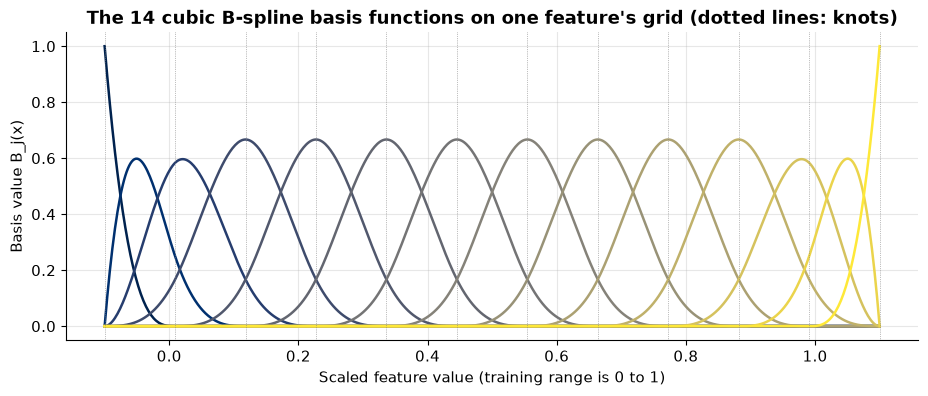

In [5]:
knots = clamped_knots()
grid01 = torch.linspace(-GRID_EXTEND, 1 + GRID_EXTEND, 601)
B = bspline_basis(grid01, knots).numpy()
print(f"knot vector ({len(knots)} knots): {[round(float(k), 3) for k in knots]}")
print(f"basis functions per feature: {B.shape[1]}")
print(f"max |sum of basis functions - 1| on the grid: {np.abs(B.sum(1) - 1).max():.2e} (partition of unity)")
print(f"smallest basis value: {B.min():.2e} (never negative)")

fig, ax = plt.subplots(figsize=(11, 4))
cmap = plt.get_cmap(SEQUENTIAL_CMAP)
for j in range(B.shape[1]):
    ax.plot(grid01, B[:, j], color=cmap(j / (B.shape[1] - 1)), lw=1.8)
for k in knots.unique():
    ax.axvline(float(k), color="grey", lw=0.5, ls=":")
ax.set_title(f"The {B.shape[1]} cubic B-spline basis functions on one feature's grid (dotted lines: knots)")
ax.set_xlabel("Scaled feature value (training range is 0 to 1)")
ax.set_ylabel("Basis value B_j(x)")
plt.show()

Takeaway: each basis function is a smooth bump that is non-zero over at most four knot spans, and at every point
the 14 functions sum to 1. A learned curve is a weighted sum of them, so changing one weight bends the curve only
locally, which is what makes the result easy to read.

## 3. One edge function, then the additive model

`BSplineEdge` holds 14 spline weights and one SiLU weight. `KAAM` keeps one edge per feature in an `nn.ModuleDict`
and passes each edge exactly one input column, so the "no interactions" property is enforced by the structure of the code
itself.

In [6]:
set_seed(SEED)
toy = KAAM(FEATURES)
n_params = sum(p.numel() for p in toy.parameters())
print(f"parameters: {n_params} = {len(FEATURES)} features x ({toy.edges['plan_cpu'].n_basis} spline weights + 1 SiLU weight) + 1 bias")

x = torch.rand(5, len(FEATURES))
contrib = toy.contributions(x)
x2 = x.clone()
x2[:, 3] = torch.rand(5)  # change one feature only
changed = (toy.contributions(x2) - contrib).abs().amax(dim=0)
print("largest change in each feature's contribution after editing feature 3 only:")
print(pd.Series(changed.detach().numpy(), index=FEATURES).round(6).to_dict())
risk_from_parts = torch.sigmoid(contrib.sum(1) + toy.bias)
print(f"max |forward - sigmoid(sum of contributions + bias)| = {(toy(x) - risk_from_parts).abs().max():.1e}")

parameters: 151 = 10 features x (14 spline weights + 1 SiLU weight) + 1 bias
largest change in each feature's contribution after editing feature 3 only:
{'plan_cpu': 0.0, 'plan_mem': 0.0, 'plan_gpu': 0.0, 'inst_num': 0.20865599811077118, 'avg_cpu_usr': 0.0, 'avg_gpu_util': 0.0, 'avg_cpu_kernel': 0.0, 'avg_load_1': 0.0, 'cap_gpu': 0.0, 'avg_net_receive': 0.0}
max |forward - sigmoid(sum of contributions + bias)| = 0.0e+00


Editing one feature changes only that feature's contribution, and the prediction is exactly the sigmoid of the
summed contributions. That exactness is the point: there is nothing to approximate when explaining a prediction.

## 4. Sanity check: recovering known curves from synthetic data

Before trusting the model on real data, give it a problem with a known answer: three features with hand-made
effects (a bump, a step and a straight line), seven pure-noise features, and labels drawn from the resulting
probabilities. If the code is right, the learned curves should match the true ones and the noise curves stay flat.

synthetic validation ROC-AUC 0.790 after 34 epochs


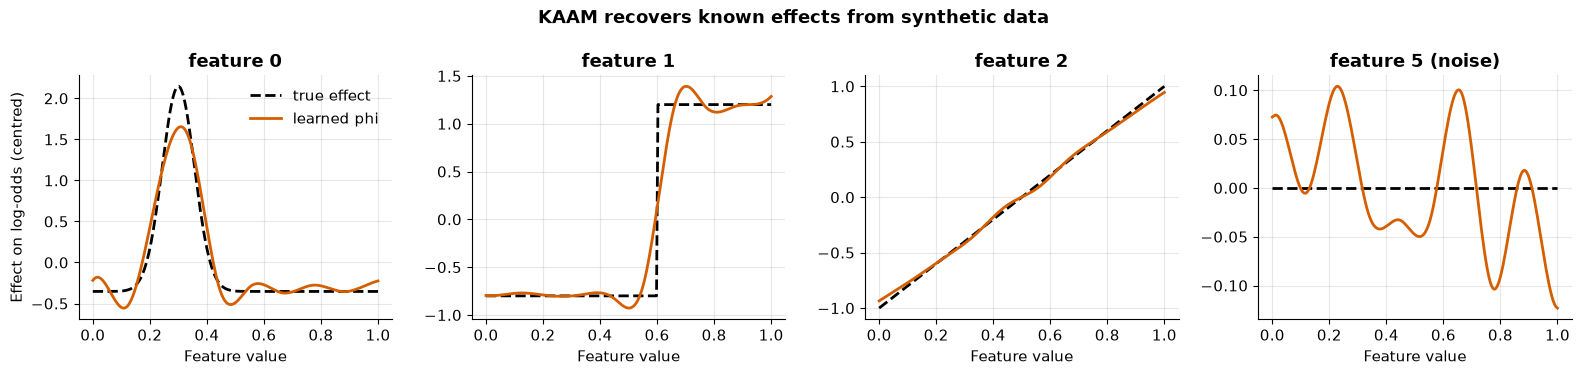

Takeaway: the learned curves track the true ones (correlations 0.98, 0.98, 1.00), and the seven noise features stay nearly flat (largest swing 0.24 log-odds, against 2.0 to 2.5 for the real effects). The step is rounded off, because a cubic spline on ten knots cannot jump.

In [7]:
def synthetic_problem(n=60_000, seed=SEED):
    """Ten uniform features; only the first three matter, through known functions."""
    rng = np.random.default_rng(seed)
    Xs = rng.uniform(0, 1, size=(n, len(FEATURES))).astype("float32")
    true = {0: lambda v: 2.5 * np.exp(-((v - 0.3) / 0.08) ** 2),   # a narrow bump
            1: lambda v: np.where(v > 0.6, 1.5, -0.5),              # a step
            2: lambda v: 2.0 * (v - 0.5)}                           # a line
    logit = sum(f(Xs[:, j]) for j, f in true.items()) - 0.5
    ys = (rng.uniform(size=n) < 1 / (1 + np.exp(-logit))).astype(int)
    return Xs, ys, true


Xs, ys, true_fns = synthetic_problem()
cut = int(0.8 * len(ys))
d_syn_tr, d_syn_va = design(Xs[:cut], knots), design(Xs[cut:], knots)
syn_model, syn_hist = fit_kaam(d_syn_tr, ys[:cut], d_syn_va, ys[cut:], lam=0.0)
print(f"synthetic validation ROC-AUC {max(syn_hist):.3f} after {len(syn_hist)} epochs")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
g = np.linspace(0, 1, 200)
for ax, j in zip(axes, [0, 1, 2, 5]):
    learned = shape_curve(syn_model, FEATURES[j], g)
    truth = true_fns[j](g) if j in true_fns else np.zeros_like(g)
    ax.plot(g, truth - truth.mean(), color=BLACK, ls="--", lw=2, label="true effect")
    ax.plot(g, learned - learned.mean(), color=VERMILLION, lw=2, label="learned phi")
    ax.set_title(f"feature {j}" + (" (noise)" if j not in true_fns else ""))
    ax.set_xlabel("Feature value")
axes[0].set_ylabel("Effect on log-odds (centred)")
axes[0].legend()
fig.suptitle("KAAM recovers known effects from synthetic data", fontweight="bold")
plt.tight_layout()
plt.show()
corr = [np.corrcoef(shape_curve(syn_model, FEATURES[j], g), true_fns[j](g))[0, 1] for j in true_fns]
noise_range = max(np.ptp(shape_curve(syn_model, FEATURES[j], g)) for j in range(3, len(FEATURES)))
true_swing = [np.ptp(true_fns[j](g)) for j in true_fns]
say(f"Takeaway: the learned curves track the true ones (correlations {', '.join(f'{c:.2f}' for c in corr)}), and the "
    f"seven noise features stay nearly flat (largest swing {noise_range:.2f} log-odds, against "
    f"{min(true_swing):.1f} to {max(true_swing):.1f} for the real effects). The step is rounded off, because a cubic "
    "spline on ten knots cannot jump.")

## 5. Training on the GPU trace: fast fitting with a precomputed design

The knots never move, so each feature's basis values depend only on the input. We compute them once per split (the
"design"), and training then fits 151 numbers with minibatch Adam on fixed arrays, which is much faster than
re-running the recursion every step. Early stopping watches validation ROC-AUC with a patience of 10 epochs. The
penalty `lambda x roughness` (squared second differences of the spline weights) pulls curves toward straight lines;
we try four strengths and keep the best on validation.

The split, clipping and scaling are the same as in part 3: stratified 70/15/15, fitted on the training part only.

In [8]:
tasks = load_tasks()
y = tasks["label"].to_numpy()
users = tasks["user_rank"].to_numpy()
split = random_split(y)
scaler = Scaler().fit(tasks.loc[split["train"], FEATURES])
X = {k: scaler.transform(tasks.loc[idx, FEATURES]) for k, idx in split.items()}
Y = {k: y[idx] for k, idx in split.items()}
t0 = time.perf_counter()
D = {k: design(X[k].to_numpy(), knots) for k in X}
print(f"{len(tasks):,} tasks; design for {len(X['train']):,} training tasks: {tuple(D['train'][0].shape)} "
      f"({D['train'][0].numel() * 4 / 1e6:.0f} MB) built in {time.perf_counter() - t0:.1f} s")

539,816 tasks; design for 377,870 training tasks: (377870, 10, 14) (212 MB) built in 2.6 s


lambda 0: best validation AUC 0.7640 at epoch 39 of 40


lambda 0.0001: best validation AUC 0.7573 at epoch 12 of 22


lambda 0.001: best validation AUC 0.7552 at epoch 14 of 22


lambda 0.01: best validation AUC 0.7510 at epoch 14 of 24
chosen lambda = 0; training took 59 s


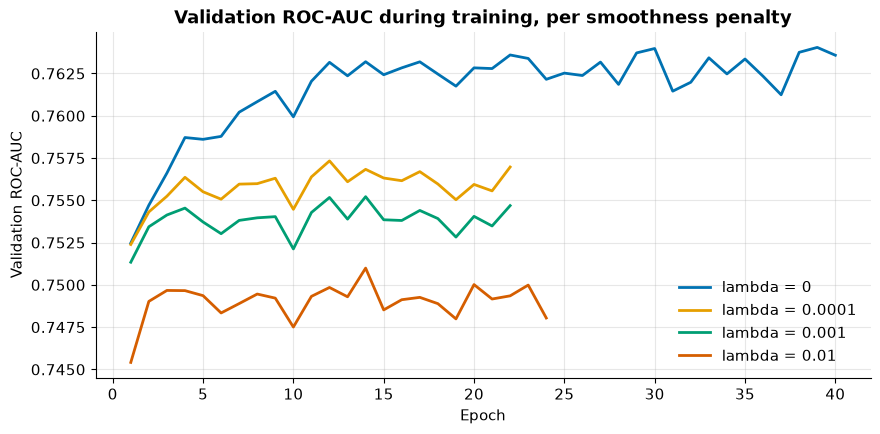

Takeaway: training stops after a few dozen epochs, and the validation AUC is highest with lambda = 0; stronger smoothing costs a little accuracy on this split. Section 7 shows what it does to the curves.

In [9]:
t0 = time.perf_counter()
fits = {}
for lam in LAMBDAS:
    model, hist = fit_kaam(D["train"], Y["train"], D["val"], Y["val"], lam)
    fits[lam] = (model, hist)
    print(f"lambda {lam:g}: best validation AUC {max(hist):.4f} at epoch {int(np.argmax(hist)) + 1} "
          f"of {len(hist)}")
best_lam = max(fits, key=lambda l: max(fits[l][1]))
kaam = fits[best_lam][0]
print(f"chosen lambda = {best_lam:g}; training took {time.perf_counter() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(10, 4.5))
for (lam, (_, hist)), color in zip(fits.items(), PALETTE):
    ax.plot(np.arange(1, len(hist) + 1), hist, color=color, lw=2, label=f"lambda = {lam:g}")
ax.set_title("Validation ROC-AUC during training, per smoothness penalty")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation ROC-AUC")
ax.legend()
plt.show()
say(f"Takeaway: training stops after a few dozen epochs, and the validation AUC is highest with lambda = {best_lam:g}; "
    "stronger smoothing costs a little accuracy on this split. Section 7 shows what it does to the curves.")

In [10]:
lr_model, lr_c = fit_lr(X["train"], Y["train"], X["val"], Y["val"])
p_kaam = 1 / (1 + np.exp(-kaam_logit(kaam, D["test"])))
p_lr = lr_model.predict_proba(X["test"])[:, 1]
res = pd.DataFrame([("logistic regression (11 parameters)", *bootstrap_auc(Y["test"], p_lr)),
                    ("KAAM (151 parameters)", *bootstrap_auc(Y["test"], p_kaam))],
                   columns=["model", "test ROC-AUC", "95% CI low", "95% CI high"]).set_index("model")
display(res.round(3))
with torch.no_grad():
    p_module = kaam(torch.from_numpy(X["test"].to_numpy().copy())).numpy()
print(f"max |KAAM.forward - fast design prediction| on the test set: {np.abs(p_module - p_kaam).max():.1e}")
auc_kaam_random = res.iloc[1, 0]
auc_lr_random = res.iloc[0, 0]
say(f"Takeaway: KAAM reaches a test ROC-AUC of {auc_kaam_random:.3f} on the random split against {auc_lr_random:.3f} "
    "for logistic regression, which is the same additive structure with straight lines instead of curves. The gain "
    "is what the curves add. The standard `nn.Module` reproduces the fast training-time predictions.")

,test ROC-AUC,95% CI low,95% CI high
model,,,
logistic regression (11 parameters),0.731,0.727,0.736
KAAM (151 parameters),0.766,0.762,0.769


max |KAAM.forward - fast design prediction| on the test set: 1.8e-07


Takeaway: KAAM reaches a test ROC-AUC of 0.766 on the random split against 0.731 for logistic regression, which is the same additive structure with straight lines instead of curves. The gain is what the curves add. The standard `nn.Module` reproduces the fast training-time predictions.

## 6. Reading the ten learned curves

Each panel is one feature's phi in raw units (requests in their trace units, telemetry as averaged), centred so its
average over training tasks is zero. Above zero pushes a task toward failure, below zero away from it. The grey
histogram shows where the training tasks lie, because a curve says little where there is no data.

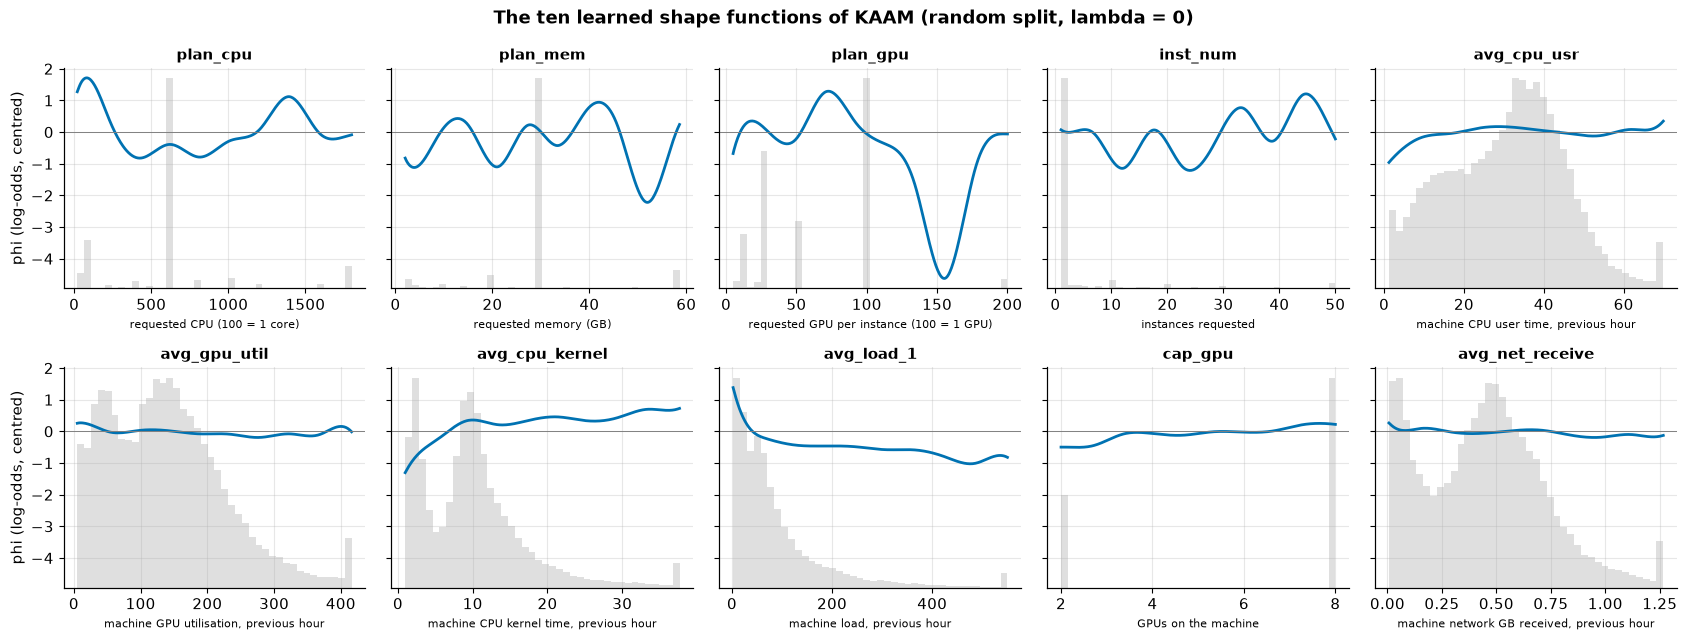

,mean |centred contribution|,curve swing (max - min)
plan_cpu,0.616,2.535
avg_load_1,0.423,2.406
avg_cpu_kernel,0.422,2.029
cap_gpu,0.306,0.757
plan_mem,0.222,3.163
plan_gpu,0.130,5.914
avg_cpu_usr,0.129,1.306
inst_num,0.125,2.418
avg_gpu_util,0.074,0.462
avg_net_receive,0.061,0.458


Takeaway: by mean absolute contribution on test tasks, `plan_cpu` and `avg_load_1` matter most. The `plan_cpu` curve peaks at 0.8 cores, right by the one-core requests (`plan_cpu` = 100) that part 5 traces to a single heavy user. Read the request curves only where the histogram has mass: requests take a few fixed values (6 cores, 29.3 GB, a quarter, half or one GPU), and between those values the spline is free to wiggle, which is where the deep `plan_gpu` dip near 150 sits.

In [11]:
def plot_shape_functions(axes, model, scaler, tasks_train, color=BLUE, label=None, centre_on=None):
    """phi_i in raw units for every feature, centred on the training mean, with the data density underneath."""
    g = np.linspace(0, 1, 300)
    out = {}
    for ax, f in zip(axes.ravel(), FEATURES):
        phi = shape_curve(model, f, g)
        x_scaled = scaler.transform(tasks_train[FEATURES])[f].to_numpy().copy() if centre_on is None else centre_on[f]
        centre = shape_curve(model, f, x_scaled).mean()
        raw = scaler.to_raw(f, g)
        unit = NET_UNIT if f == "avg_net_receive" else 1.0  # plot network bytes in GB
        ax.plot(raw / unit, phi - centre, color=color, lw=2, label=label)
        out[f] = (raw, phi - centre)
        ax.axhline(0, color="grey", lw=0.7)
        ax.set_title(f, fontsize=11)
        ax.set_xlabel(FEATURE_NOTES[f].replace("bytes", "GB") if unit != 1.0 else FEATURE_NOTES[f], fontsize=8)
    return out


def add_density(axes, tasks_train, scaler):
    """Grey histogram of the clipped training values on a twin axis of each panel."""
    for ax, f in zip(axes.ravel(), FEATURES):
        v = tasks_train[f].clip(scaler.lo[f], scaler.hi[f]) / (NET_UNIT if f == "avg_net_receive" else 1.0)
        twin = ax.twinx()
        twin.hist(v, bins=40, color="grey", alpha=0.25)
        twin.set_yticks([])
        twin.grid(False)
        ax.set_zorder(twin.get_zorder() + 1)
        ax.patch.set_visible(False)


train_tasks = tasks.loc[split["train"]]
x_scaled_train = {f: X["train"][f].to_numpy().copy() for f in FEATURES}  # writable copies for torch
fig, axes = plt.subplots(2, 5, figsize=(17, 6.5), sharey=True)
curves = plot_shape_functions(axes, kaam, scaler, train_tasks, centre_on=x_scaled_train)
add_density(axes, train_tasks, scaler)
for ax in axes[:, 0]:
    ax.set_ylabel("phi (log-odds, centred)")
fig.suptitle(f"The ten learned shape functions of KAAM (random split, lambda = {best_lam:g})", fontweight="bold")
plt.tight_layout()
plt.show()

contrib_test = kaam_contributions(kaam, D["test"])
importance = pd.Series(np.abs(contrib_test - contrib_test.mean(0)).mean(0), index=FEATURES).sort_values(ascending=False)
swing = pd.Series({f: np.ptp(curves[f][1]) for f in FEATURES}).reindex(importance.index)
display(pd.DataFrame({"mean |centred contribution|": importance, "curve swing (max - min)": swing}).round(3))
phi_cpu = curves["plan_cpu"]
peak_cores = phi_cpu[0][np.argmax(phi_cpu[1])] / 100
say(f"Takeaway: by mean absolute contribution on test tasks, `{importance.index[0]}` and `{importance.index[1]}` "
    f"matter most. The `plan_cpu` curve peaks at {peak_cores:.1f} cores, right by the one-core requests "
    "(`plan_cpu` = 100) that part 5 traces to a single heavy user. Read the request curves only where the histogram has mass: requests take a few fixed "
    "values (6 cores, 29.3 GB, a quarter, half or one GPU), and between those values the spline is free to wiggle, "
    "which is where the deep `plan_gpu` dip near 150 sits.")

## 7. What the smoothness penalty does

The same model trained with the strongest penalty tried (lambda = 0.01) next to the chosen one, for the two features
with the largest swing.

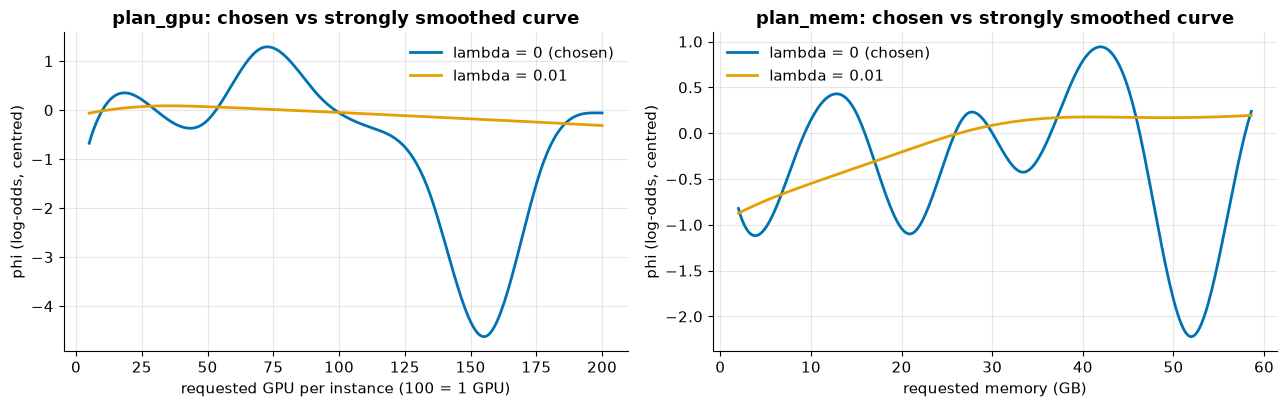

roughness of the fitted spline weights per lambda: {'0': 2749.23, '0.0001': 16.44, '0.001': 2.58, '0.01': 0.37}


Takeaway: the strongest penalty flattens the swings that sit between observed request values, including the `plan_gpu` dip, and keeps the broad trend. It costs validation AUC (0.764 with lambda = 0 against 0.751 with lambda = 0.01), so part of what the unpenalised curves gain on a random split comes from those sharp, data-starved shapes.

In [12]:
smooth_model = fits[max(LAMBDAS)][0]
top2 = list(swing.sort_values(ascending=False).index[:2])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), squeeze=False)
g = np.linspace(0, 1, 300)
for ax, f in zip(axes[0], top2):
    for model, color, lab in [(kaam, BLUE, f"lambda = {best_lam:g} (chosen)"), (smooth_model, ORANGE, f"lambda = {max(LAMBDAS):g}")]:
        phi = shape_curve(model, f, g)
        phi = phi - shape_curve(model, f, x_scaled_train[f]).mean()
        ax.plot(scaler.to_raw(f, g), phi, color=color, lw=2, label=lab)
    ax.set_title(f"{f}: chosen vs strongly smoothed curve")
    ax.set_xlabel(FEATURE_NOTES[f])
    ax.set_ylabel("phi (log-odds, centred)")
    ax.legend()
plt.tight_layout()
plt.show()
rough = {lam: float(roughness(torch.stack([m.edges[n].spline_weight for n in FEATURES])).detach())
         for lam, (m, _) in fits.items()}
print("roughness of the fitted spline weights per lambda:", {f"{k:g}": round(v, 2) for k, v in rough.items()})
val_best = {lam: max(h) for lam, (_, h) in fits.items()}
say(f"Takeaway: the strongest penalty flattens the swings that sit between observed request values, including the "
    f"`plan_gpu` dip, and keeps the broad trend. It costs validation AUC ({val_best[best_lam]:.3f} with lambda = "
    f"{best_lam:g} against {val_best[max(LAMBDAS)]:.3f} with lambda = {max(LAMBDAS):g}), so part of what the "
    "unpenalised curves gain on a random split comes from those sharp, data-starved shapes.")

## 8. Users the model has never seen

Part 3 showed that LightGBM's random-split score collapses when whole users are held out. The same five
user-grouped folds for KAAM and logistic regression, with lambda fixed to the value chosen above:

,user 1 in test,KAAM,logistic regression,KAAM epochs
fold,,,,
0,False,0.582,0.568,16
1,False,0.547,0.498,13
2,False,0.579,0.526,37
3,False,0.485,0.782,29
4,True,0.751,0.620,11


grouped evaluation took 79 s


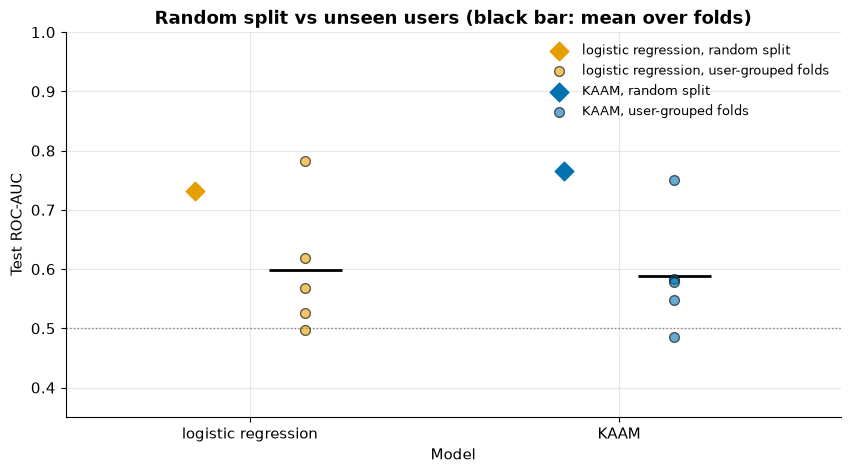

Takeaway: KAAM drops from 0.766 on the random split to a mean of 0.589 with users held out (folds 0.485 to 0.751). It beats logistic regression on 4 of 5 folds, while logistic regression averages 0.599 because of one strong fold (0.782). The spread between folds is larger than the gap between the models, and part 3 shows LightGBM falling further on the same folds.

In [13]:
t0 = time.perf_counter()
rows = []
for k, fold in enumerate(user_grouped_folds(y, users)):
    sc = Scaler().fit(tasks.loc[fold["train"], FEATURES])
    Xf = {p: sc.transform(tasks.loc[idx, FEATURES]) for p, idx in fold.items()}
    Yf = {p: y[idx] for p, idx in fold.items()}
    Df = {p: design(Xf[p].to_numpy(), knots) for p in Xf}
    m, h = fit_kaam(Df["train"], Yf["train"], Df["val"], Yf["val"], best_lam)
    lr_m, _ = fit_lr(Xf["train"], Yf["train"], Xf["val"], Yf["val"])
    rows.append({"fold": k, "user 1 in test": bool(1 in set(users[fold["test"]])),
                 "KAAM": roc_auc_score(Yf["test"], kaam_logit(m, Df["test"])),
                 "logistic regression": roc_auc_score(Yf["test"], lr_m.predict_proba(Xf["test"])[:, 1]),
                 "KAAM epochs": len(h)})
grouped = pd.DataFrame(rows).set_index("fold")
display(grouped.round(3))
print(f"grouped evaluation took {time.perf_counter() - t0:.0f} s")


def plot_protocols(ax, res, grouped):
    """Random-split test AUC (diamond) next to the user-grouped folds (dots) for KAAM and logistic regression."""
    for i, (m, rkey, color) in enumerate([("logistic regression", res.index[0], ORANGE), ("KAAM", res.index[1], BLUE)]):
        ax.scatter([i - 0.15], [res.loc[rkey, "test ROC-AUC"]], marker="D", s=90, color=color, zorder=3,
                   label=f"{m}, random split")
        ax.scatter(np.full(len(grouped), i + 0.15), grouped[m], s=50, color=color, alpha=0.6, edgecolor=BLACK,
                   zorder=3, label=f"{m}, user-grouped folds")
        ax.hlines(grouped[m].mean(), i + 0.05, i + 0.25, color=BLACK, lw=2)
    ax.axhline(0.5, color="grey", ls=":", lw=1)
    ax.set_xticks([0, 1], ["logistic regression", "KAAM"])
    ax.set_xlim(-0.5, 1.6)
    ax.set_ylim(0.35, 1.0)
    ax.set_title("Random split vs unseen users (black bar: mean over folds)")
    ax.set_xlabel("Model")
    ax.set_ylabel("Test ROC-AUC")
    ax.legend(fontsize=9, loc="upper right")


fig, ax = plt.subplots(figsize=(10, 5))
plot_protocols(ax, res, grouped)
plt.show()
kaam_wins = int((grouped["KAAM"] > grouped["logistic regression"]).sum())
say(f"Takeaway: KAAM drops from {auc_kaam_random:.3f} on the random split to a mean of {grouped['KAAM'].mean():.3f} "
    f"with users held out (folds {grouped['KAAM'].min():.3f} to {grouped['KAAM'].max():.3f}). It beats logistic "
    f"regression on {kaam_wins} of {len(grouped)} folds, while logistic regression averages "
    f"{grouped['logistic regression'].mean():.3f} because of one strong fold "
    f"({grouped['logistic regression'].max():.3f}). The spread between folds is larger than the gap between the "
    "models, and part 3 shows LightGBM falling further on the same folds.")

In [14]:
fig = plt.figure(figsize=(12.8, 7.2), dpi=100)
axes = fig.subplots(2, 5, sharey=True)
plot_shape_functions(axes, kaam, scaler, train_tasks, centre_on=x_scaled_train)
for ax in axes[:, 0]:
    ax.set_ylabel("phi (log-odds)")
fig.suptitle("KAAM: one learned B-spline curve per feature (GPU task failure, Alibaba PAI 2020)", fontweight="bold")
fig.tight_layout()
fig.savefig(WORKING / "cover.png", dpi=100)
plt.close(fig)
print("saved cover.png (the ten shape functions)")

saved cover.png (the ten shape functions)


## 9. What we found

In [15]:
say(f"""- A complete KAAM, with its training loop, fits in one code cell of PyTorch: a Cox-de Boor basis, one `BSplineEdge` per feature in an
  `nn.ModuleDict`, and 151 parameters in total.
- On synthetic data it recovers known effects (curve correlations {', '.join(f'{c:.2f}' for c in corr)}) and leaves
  noise features flat.
- On the GPU trace it reaches a test ROC-AUC of {auc_kaam_random:.3f} on a random split, against {auc_lr_random:.3f}
  for logistic regression.
- With users held out its mean falls to {grouped['KAAM'].mean():.3f}, against {grouped['logistic regression'].mean():.3f}
  for logistic regression.""")

- A complete KAAM, with its training loop, fits in one code cell of PyTorch: a Cox-de Boor basis, one `BSplineEdge` per feature in an
  `nn.ModuleDict`, and 151 parameters in total.
- On synthetic data it recovers known effects (curve correlations 0.98, 0.98, 1.00) and leaves
  noise features flat.
- On the GPU trace it reaches a test ROC-AUC of 0.766 on a random split, against 0.731
  for logistic regression.
- With users held out its mean falls to 0.589, against 0.599
  for logistic regression.

### Limitations

- One seed per fit; the KANVAS study averages five seeds and reports paired bootstrap intervals.
- An additive model cannot represent interactions (for example, a CPU request that is risky only on 2-GPU
  machines). On a random split that costs accuracy against LightGBM.
- Curves are only meaningful where the training data has support; the histograms show where that is.

### Ideas to try

- Add a small number of chosen pairwise terms (a GA2M-style KAAM) and see whether the grouped score moves.
- Replace uniform knots with knots at training quantiles, so the resolution follows the data.
- Train with users held out from the start and compare the curves with the random-split ones.

### The series

1. [Alibaba PAI GPU trace 2020: a complete EDA](https://www.kaggle.com/code/swapnilshukla007/alibaba-pai-gpu-trace-2020-a-complete-eda)
2. [Where cluster GPUs sit idle: utilization, over-requesting and fragmentation](https://www.kaggle.com/code/swapnilshukla007/where-cluster-gpus-sit-idle)
3. [Predicting GPU task failure: a LightGBM baseline explained with SHAP](https://www.kaggle.com/code/swapnilshukla007/predicting-gpu-task-failure-lightgbm-and-shap)
4. Kolmogorov-Arnold additive models from scratch: B-spline edge functions in PyTorch (this notebook)
5. [Reading the splines: KAAM shape functions vs SHAP on the same tasks](https://www.kaggle.com/code/swapnilshukla007/reading-the-splines-kaam-curves-vs-shap)

If something here is wrong or unclear, a comment helps more than anything; an upvote helps others find it.